# Clustering Teks Artikel Komdigi dengan K-Means

Notebook ini mengadaptasi materi clustering ke `komdigi_hoaks.csv`. Teks judul, ringkasan, dan isi artikel diubah menjadi fitur TF-IDF. Contoh K-Means manual, pemilihan jumlah cluster, Spectral Clustering, evaluasi terhadap topik, serta interpretasi kata per cluster menggunakan artikel pada dataset ini.

Clustering bersifat unsupervised. Kolom `topics` hanya dipakai untuk interpretasi/evaluasi eksternal, bukan untuk melatih cluster; topik bukan label benar atau salahnya klaim.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.metrics import pairwise_distances_argmin

# Dukung eksekusi dari root repository maupun folder notebook.
data_candidates = [
    Path("../../data/komdigi_hoaks.csv"),
]
data_path = next((path for path in data_candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("File komdigi_hoaks.csv tidak ditemukan.")

df = pd.read_csv(data_path)
print(f"Lokasi dataset: {data_path.resolve()}")
print("Ukuran awal:", df.shape)

# Hapus artikel dengan URL duplikat, lalu gabungkan kolom teks.
df = df.drop_duplicates(subset="url", keep="first").copy()
text_columns = ["title", "excerpt", "body_text"]
df[text_columns] = df[text_columns].fillna("").astype(str)
df["article_text"] = (
    df[text_columns]
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
df["topics"] = df["topics"].str.strip()

vectorizer = TfidfVectorizer(
    max_features=5000,
    min_df=2,
    ngram_range=(1, 2),
    sublinear_tf=True,
)
X = vectorizer.fit_transform(df["article_text"])
print("Artikel setelah deduplikasi:", len(df))
print("Matriks TF-IDF:", X.shape)
display(df[["title", "topics", "article_text"]].head())

Lokasi dataset: D:\Kuliah\Kelas\Semester 5\Pembelajaran Mesin\TUGAS\PRAKTIKUM\data\komdigi_hoaks.csv
Ukuran awal: (4176, 13)
Artikel setelah deduplikasi: 4162
Matriks TF-IDF: (4162, 5000)


,title,topics,article_text
0,[HOAKS] Tautan Pencairan BSU September 2026 Se...,Hoaks,[HOAKS] Tautan Pencairan BSU September 2026 Se...
1,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...,Hoaks,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...
2,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...,Hoaks,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...
3,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...,Hoaks,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...
4,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...,Hoaks,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...


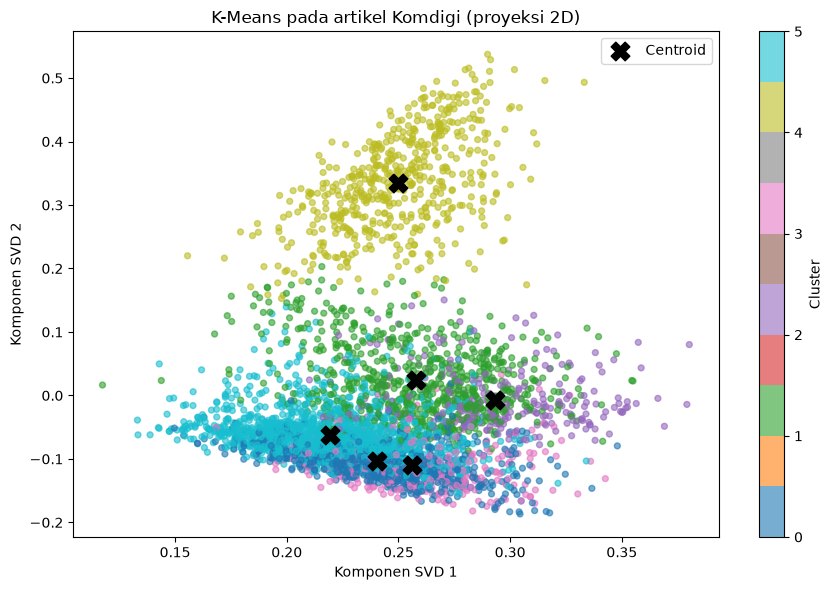

Ukuran cluster:


,jumlah artikel
cluster,
0,809
1,709
2,284
3,373
4,559
5,1428


Proporsi variansi SVD 2D: 0.0247


In [2]:
# K-Means pada matriks TF-IDF; jumlah cluster diset 6 untuk contoh awal.
n_clusters = 6
kmeans = KMeans(n_clusters=n_clusters, n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(X)
df["cluster"] = cluster_labels

# SVD hanya untuk memproyeksikan vektor teks ke 2D agar dapat diplot.
svd_2d = TruncatedSVD(n_components=2, random_state=42)
X_2d = svd_2d.fit_transform(X)
centers_2d = svd_2d.transform(kmeans.cluster_centers_)

plt.figure(figsize=(9, 6))
points = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=cluster_labels,
                     cmap="tab10", s=18, alpha=0.6)
plt.scatter(centers_2d[:, 0], centers_2d[:, 1], c="black", marker="X",
            s=180, label="Centroid")
plt.xlabel("Komponen SVD 1")
plt.ylabel("Komponen SVD 2")
plt.title("K-Means pada artikel Komdigi (proyeksi 2D)")
plt.colorbar(points, label="Cluster")
plt.legend()
plt.tight_layout()
plt.show()
print("Ukuran cluster:")
display(df["cluster"].value_counts().sort_index().rename("jumlah artikel").to_frame())
print("Proporsi variansi SVD 2D:", round(svd_2d.explained_variance_ratio_.sum(), 4))

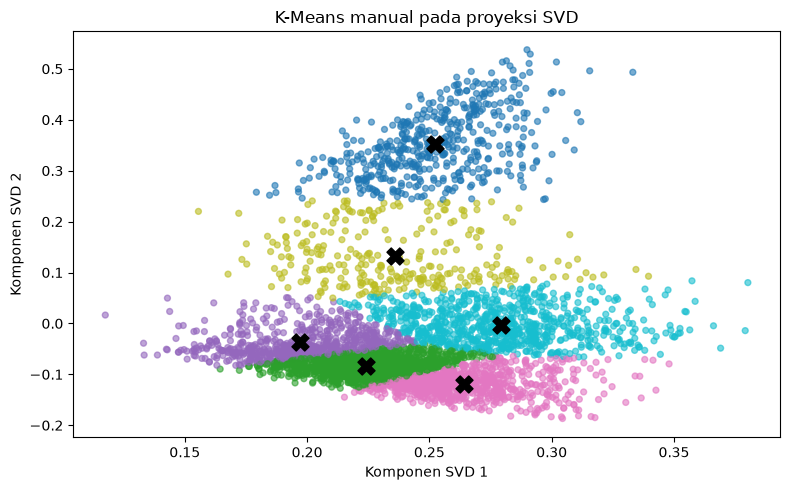

In [3]:
# Implementasi K-Means sederhana pada proyeksi 2D untuk memahami langkah algoritma.
def find_clusters(data, n_clusters, random_state=2, max_iter=100):
    rng = np.random.RandomState(random_state)
    centers = data[rng.choice(data.shape[0], n_clusters, replace=False)].copy()

    for _ in range(max_iter):
        labels = pairwise_distances_argmin(data, centers)
        new_centers = centers.copy()
        for cluster_id in range(n_clusters):
            points_in_cluster = data[labels == cluster_id]
            if len(points_in_cluster) > 0:
                new_centers[cluster_id] = points_in_cluster.mean(axis=0)
        if np.allclose(centers, new_centers):
            centers = new_centers
            break
        centers = new_centers

    labels = pairwise_distances_argmin(data, centers)
    return centers, labels

manual_centers, manual_labels = find_clusters(X_2d, n_clusters=6, random_state=2)
plt.figure(figsize=(8, 5))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=manual_labels, cmap="tab10", s=18, alpha=0.6)
plt.scatter(manual_centers[:, 0], manual_centers[:, 1], c="black", marker="X", s=150)
plt.title("K-Means manual pada proyeksi SVD")
plt.xlabel("Komponen SVD 1")
plt.ylabel("Komponen SVD 2")
plt.tight_layout()
plt.show()

In [4]:
# Pengaruh inisialisasi centroid: ulangi K-Means dengan seed berbeda.
seed_results = []
for seed in range(10):
    model = KMeans(n_clusters=6, n_init=1, random_state=seed)
    model.fit(X)
    seed_results.append((seed, model.inertia_))

seed_results = sorted(seed_results, key=lambda result: result[1])
print("SSE (inertia) terbaik dari 10 inisialisasi:")
for seed, inertia in seed_results:
    print(f"seed={seed}; SSE={inertia:.4f}")

SSE (inertia) terbaik dari 10 inisialisasi:
seed=2; SSE=3722.5156
seed=9; SSE=3722.6260
seed=4; SSE=3722.8941
seed=7; SSE=3724.6458
seed=1; SSE=3725.1074
seed=3; SSE=3725.3907
seed=0; SSE=3728.9601
seed=6; SSE=3731.0479
seed=8; SSE=3731.0584
seed=5; SSE=3732.0925


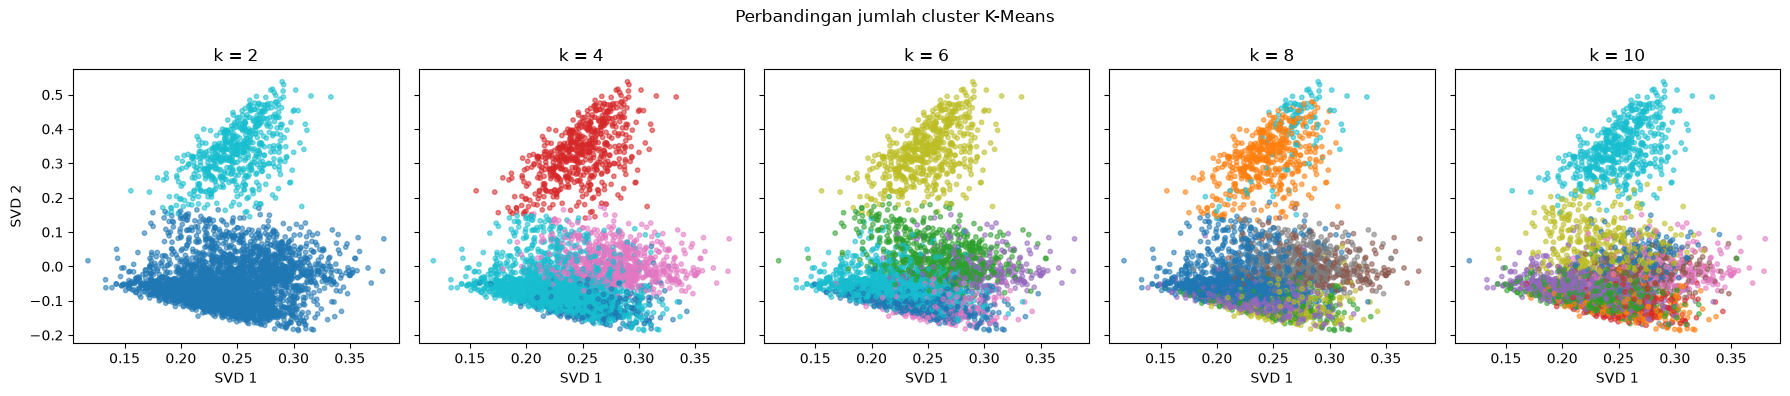

In [5]:
# Bandingkan solusi dengan jumlah cluster berbeda pada ruang TF-IDF.
cluster_counts = [2, 4, 6, 8, 10]
models_by_k = {}
for k in cluster_counts:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    models_by_k[k] = model.fit_predict(X)

fig, axes = plt.subplots(1, len(cluster_counts), figsize=(18, 4), sharex=True, sharey=True)
for ax, k in zip(axes, cluster_counts):
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=models_by_k[k], cmap="tab10", s=10, alpha=0.55)
    ax.set_title(f"k = {k}")
    ax.set_xlabel("SVD 1")
axes[0].set_ylabel("SVD 2")
fig.suptitle("Perbandingan jumlah cluster K-Means")
plt.tight_layout()
plt.show()

c:\Users\qulbiazzumi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


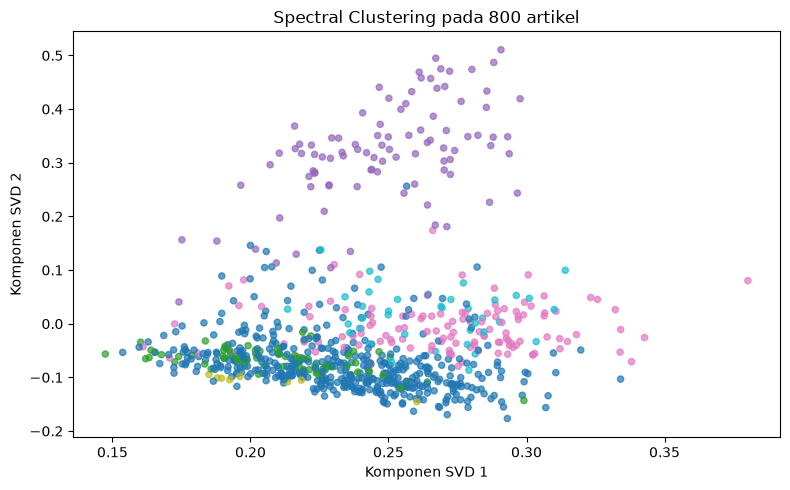

Jumlah artikel per cluster Spectral:


,jumlah artikel
0,462
1,71
2,95
3,123
4,10
5,39


In [6]:
# Spectral Clustering pada sampel agar komputasi nearest-neighbor tetap ringan.
sample_size = min(800, len(df))
rng = np.random.RandomState(42)
sample_indices = np.sort(rng.choice(len(df), sample_size, replace=False))
X_sample = X[sample_indices]

spectral = SpectralClustering(
    n_clusters=6,
    affinity="nearest_neighbors",
    n_neighbors=10,
    assign_labels="kmeans",
    random_state=42,
)
spectral_labels = spectral.fit_predict(X_sample)

plt.figure(figsize=(8, 5))
plt.scatter(X_2d[sample_indices, 0], X_2d[sample_indices, 1],
            c=spectral_labels, cmap="tab10", s=20, alpha=0.7)
plt.title(f"Spectral Clustering pada {sample_size} artikel")
plt.xlabel("Komponen SVD 1")
plt.ylabel("Komponen SVD 2")
plt.tight_layout()
plt.show()
print("Jumlah artikel per cluster Spectral:")
display(pd.Series(spectral_labels).value_counts().sort_index().rename("jumlah artikel").to_frame())

In [7]:
# Evaluasi eksternal menggunakan topics hanya untuk membandingkan hasil clustering.
# ARI dan NMI tidak memerlukan nomor cluster yang sama dengan nomor label topik.
ari = adjusted_rand_score(df["topics"], cluster_labels)
nmi = normalized_mutual_info_score(df["topics"], cluster_labels)
print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")
print("Tabulasi cluster terhadap topik (untuk interpretasi, bukan supervised training):")
display(pd.crosstab(df["cluster"], df["topics"]))

Adjusted Rand Index (ARI): 0.0385
Normalized Mutual Information (NMI): 0.1182
Tabulasi cluster terhadap topik (untuk interpretasi, bukan supervised training):


topics,Hoaks,Kesehatan,Masyarakat Digital,Pejabat Publik,Penipuan,Program/Kebijakan
cluster,,,,,,
0,756,0,15,7,7,24
1,515,0,18,0,170,6
2,217,0,3,1,63,0
3,331,6,3,0,32,1
4,402,0,31,123,3,0
5,1303,50,32,4,11,28


In [8]:
# Interpretasi cluster menggunakan istilah dengan bobot centroid TF-IDF tertinggi.
feature_names = vectorizer.get_feature_names_out()
for cluster_id, centroid in enumerate(kmeans.cluster_centers_):
    top_indices = np.argsort(centroid)[-12:][::-1]
    top_terms = feature_names[top_indices]
    print(f"Cluster {cluster_id}: {', '.join(top_terms)}")

Cluster 0: presiden, prabowo, presiden prabowo, jokowi, yang, video, turnbackhoax, turnbackhoax id, di, id, tidak, com
Cluster 1: tautan, resmi, pendaftaran, yang, bank, situs, melalui, akun, untuk, informasi, dan, undian
Cluster 2: lowongan, lowongan kerja, kerja, tautan, pt, pendaftaran, laman, id, telegram, lowongan pekerjaan, turnbackhoax, rekrutmen
Cluster 3: ai, video, artificial, artificial intelligence, intelligence, intelligence ai, persen, probabilitas, hasil, bantuan, moderation, hive
Cluster 4: whatsapp, akun whatsapp, akun, mengatasnamakan, whatsapp mengatasnamakan, yang mengatasnamakan, hoaks akun, kabupaten, nomor, akun tersebut, whatsapp yang, penipuan
Cluster 5: di, yang, video, dan, hoaks, pada, tidak, dari, tersebut, com, bahwa, unggahan
